In [1]:
# 0. Entorno. Fix de la práctica 01: Ultralytics/TensorBoard buscan el ejecutable 'tensorboard' en el PATH,
#    y en Windows con conda el kernel de Jupyter no siempre lo tiene -> se le da la ruta exacta.
import os, sys, json
from pathlib import Path

os.environ['TENSORBOARD_BINARY'] = str(Path(sys.executable).parent / 'Scripts' / 'tensorboard.exe')
print('Python:', sys.executable)
print('TENSORBOARD_BINARY:', os.environ['TENSORBOARD_BINARY'], '| existe:', Path(os.environ['TENSORBOARD_BINARY']).exists())

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
# En un worktree de agente, definir INVENTARIO_DATOS / INVENTARIO_MODELOS antes de abrir el notebook.
from src.config import DIR_DATOS, DIR_MODELOS, UMBRAL_DET
from scripts.detector_entrenar import DIR_RUNS, HIPER, AUMENTO, VARIANTES
print('datos:', DIR_DATOS, '\nmodelos:', DIR_MODELOS, '\nruns:', DIR_RUNS)

Python: C:\Users\limber\anaconda3\envs\inventariovision\python.exe
TENSORBOARD_BINARY: C:\Users\limber\anaconda3\envs\inventariovision\Scripts\tensorboard.exe | existe: True
datos: C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\datos 
modelos: C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\modelos 
runs: C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\runs\detector


# 04 · Detector YOLO: fine-tuning para contar bebidas en un estante

**Objetivo del sistema:** el celular fotografía el estante y el servidor cuenta cuántas bebidas hay de cada
producto. Este notebook cubre la parte de **detección**: encontrar *dónde* está cada bebida.

## Detección vs. clasificación

| | Clasificación | Detección |
|---|---|---|
| Entrada | una imagen (o un recorte) | una imagen completa |
| Salida | **una** etiqueta + probabilidad | **N cajas** (x, y, ancho, alto) + clase + confianza por caja |
| Pregunta | *¿qué es esto?* | *¿dónde hay objetos y qué son?* |
| Ejemplo aquí | CNN Keras: "este recorte es `fanta_lata`" | YOLO: "hay 14 productos en estas posiciones" |

Para **contar** hace falta detección: cada caja es una unidad. Probamos dos arquitecturas:

- **Variante A (la del sistema):** YOLO de **una sola clase** (`producto`) + CNN clasificadora por recorte.
  El detector solo aprende "esto es una bebida" (tarea más fácil, se pueden juntar todos los datasets
  aunque tengan marcas distintas); la marca la decide una CNN especializada mirando el recorte de cerca.
- **Variante B (línea base):** YOLO **multiclase** con las 9 clases de `config/clases.json`: detecta y
  clasifica en una sola pasada. Es más simple, pero cada clase tiene menos ejemplos y la marca se decide
  con la imagen reducida a 640 px, donde un logo ocupa pocos píxeles.

Antes de entrenar se midió la **línea base sin entrenar** (`yolo26n` de COCO, clase `bottle`, conf 0.25) sobre
90 fotos (`datos/viabilidad/INFORME.md`): **MAE de conteo 9.54, 12 % de fotos exactas, P 0.99, R 0.20**.
COCO casi no se equivoca cuando marca algo, pero se le escapa el 80 % de las bebidas: hay que entrenar.

In [2]:
# 1. Los datos: cuántas imágenes hay por split y de qué dataset de origen vienen
import pandas as pd

def composicion(variante):
    d = DIR_DATOS / 'fusion' / VARIANTES[variante]
    filas = []
    for s in ('train', 'val', 'test'):
        for p in (d / 'images' / s).glob('*'):
            filas.append({'split': s, 'origen': p.name.split('__')[0]})
    if not filas:
        return pd.DataFrame()
    return pd.DataFrame(filas).value_counts().unstack('split', fill_value=0)[['train', 'val', 'test']]

for v in VARIANTES:
    print(f'== {v}'); print(composicion(v)); print()

== 1clase
split                train   val  test
origen                                
darians_bottle       14355  1827  1801
lamar_grocery_color    877   117   145
rosd_final_hr         2552   344   329
soda_bottles          1776   238   229

== multiclase
split                train  val  test
origen                               
darians_bottle        3185  414   367
lamar_grocery_color    293   40    43
rosd_final_hr          993  144   133



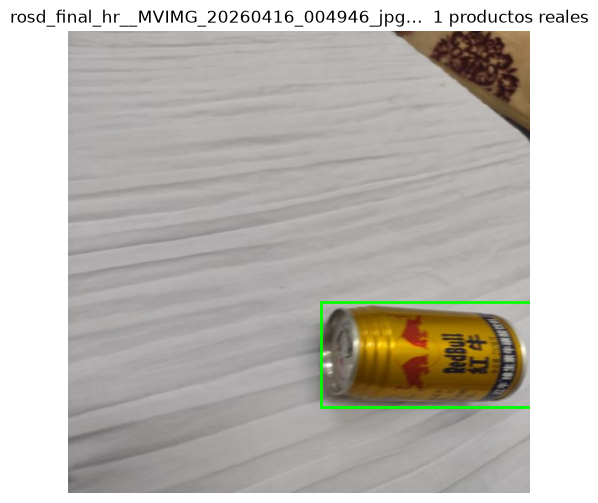

In [3]:
# 2. Una imagen de ejemplo con sus cajas reales (formato YOLO: clase xc yc w h, normalizado 0-1)
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

d = DIR_DATOS / 'fusion' / 'detector_1clase'
cands = sorted((d / 'images' / 'test').glob('rosd_final_hr__*'))
if cands:
    img_ej = random.Random(3).choice(cands)
    im = Image.open(img_ej)
    W, H = im.size
    fig, ax = plt.subplots(figsize=(6, 6)); ax.imshow(im); ax.axis('off')
    lineas = (d / 'labels' / 'test' / (img_ej.stem + '.txt')).read_text().splitlines()
    for l in lineas:
        _, xc, yc, w, h = map(float, l.split()[:5])
        ax.add_patch(patches.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H, fill=False, color='lime', lw=2))
    ax.set_title(f'{img_ej.name[:40]}…  {len(lineas)} productos reales')
    plt.show()

## Fuga de datos (data leakage)

La selección de 90 fotos de la viabilidad salió de los splits *test/valid* **originales** de Roboflow.
Al fusionar, el agente Datos rearmó los splits por foto original, así que muchas de esas fotos terminaron en
**train**. Si evaluáramos el detector entrenado sobre esas 90 fotos, estaría "viendo el examen" que ya estudió:
el número sería optimista. Lo verificamos con `datos/fusion/_indice_imagenes.csv` (se considera fuga si la
misma foto original, o una copia aumentada suya, está en train).

In [4]:
# 3. Verificación de fuga: selección de viabilidad vs. splits del fusionado
from scripts.detector_evaluar import verificar_fuga
fuga = verificar_fuga('1clase')
fuga.groupby(['dataset', 'fuga']).size().unstack(fill_value=0)

dataset                     split_fusion
roboflow-100__soda-bottles  test             3
                            train           36
                            val              6
rosd__final_hr              test             2
                            train           39
                            val              4
Fotos de la selección con la misma foto en TRAIN del fusionado: 75 de 90


fuga,False,True
dataset,,
roboflow-100__soda-bottles,9,36
rosd__final_hr,6,39


**Conclusión:** la comparación justa con la línea base se hace (a) sobre las fotos de la selección **sin fuga**
y, sobre todo, (b) sobre el split **test** del fusionado, corriendo también el modelo COCO sin entrenar sobre
esas mismas imágenes (`detector_evaluar.py conteo --pesos yolo26n.pt --filtrar-clase bottle`).

## Transfer learning (fine-tuning desde COCO)

Una red convolucional aprende en capas: las primeras detectan bordes y texturas, las intermedias formas,
las últimas objetos completos. Esas primeras capas sirven para casi cualquier imagen. Por eso **no** se
entrena desde cero: se parte de `yolo26n.pt`, entrenado con las 118 000 imágenes de COCO (que ya incluye
`bottle` y `cup`), se reemplaza la cabeza de salida (80 clases → 1 o 9) y se **reentrena toda la red** con
nuestros datos y una tasa de aprendizaje baja. Ventajas: converge en decenas de épocas en vez de cientos,
necesita miles de imágenes en vez de cientos de miles, y generaliza mejor.

## Aumento de datos

Ultralytics transforma cada imagen al vuelo en cada época, así el modelo nunca ve dos veces exactamente la
misma foto (menos sobreajuste):

| Parámetro | Valor | Por qué |
|---|---|---|
| `mosaic` | 1.0 | pega 4 fotos en una: más objetos por lote, objetos chicos y contextos variados; se apaga las últimas 10 épocas (`close_mosaic`) para terminar con fotos "naturales" |
| `hsv_h/s/v` | 0.015 / 0.7 / 0.4 | cambios de tono, saturación y brillo: iluminación de distintos comercios |
| `scale`, `translate` | 0.5, 0.1 | foto más cerca/lejos y corrida |
| `flipud` | **0** | en un estante nada está cabeza abajo: voltear verticalmente enseña casos imposibles |
| `fliplr` | **0.5 en 1clase, 0 en multiclase** | ver abajo |

**¿Conviene el espejo horizontal (`fliplr`)?** Espejar invierte logos y texto.
- En el detector de **1 clase** es inofensivo: una botella espejada sigue siendo "producto" (forma, tapa,
  etiqueta siguen ahí) y duplica la variedad de posiciones y fondos → **`fliplr=0.5`**.
- En el **multiclase** la marca se reconoce en parte por el texto ("Coca-Cola", "Sprite"). El texto espejado
  nunca aparece en una foto real, y el modelo tendría que aprender cada marca "al derecho y al revés",
  gastando capacidad en patrones que no existen → **`fliplr=0`**.

In [5]:
# 4. Hiperparámetros que usan scripts/detector_entrenar.py y el notebook de Colab
print(json.dumps(HIPER, indent=1))
print(json.dumps(AUMENTO, indent=1))

{
 "epochs": 60,
 "patience": 15,
 "imgsz": 640,
 "batch": 16,
 "optimizer": "auto",
 "cos_lr": false,
 "seed": 0,
 "deterministic": false,
 "plots": true
}
{
 "1clase": {
  "flipud": 0.0,
  "mosaic": 1.0,
  "close_mosaic": 10,
  "hsv_h": 0.015,
  "hsv_s": 0.7,
  "hsv_v": 0.4,
  "degrees": 0.0,
  "translate": 0.1,
  "scale": 0.5,
  "mixup": 0.0,
  "fliplr": 0.5
 },
 "multiclase": {
  "flipud": 0.0,
  "mosaic": 1.0,
  "close_mosaic": 10,
  "hsv_h": 0.015,
  "hsv_s": 0.7,
  "hsv_v": 0.4,
  "degrees": 0.0,
  "translate": 0.1,
  "scale": 0.5,
  "mixup": 0.0,
  "fliplr": 0.0
 }
}


## Métricas de detección

- **IoU** (*Intersection over Union*) = área(caja predicha ∩ caja real) / área(caja predicha ∪ caja real).
  Una detección cuenta como **verdadero positivo (TP)** si su IoU con una caja real (de la misma clase) es ≥ umbral.
- **Precisión P** = TP / (TP + FP): de lo que marcó, qué parte era real. P baja → cuenta de más.
- **Recall R** = TP / (TP + FN): de lo real, qué parte encontró. R bajo → cuenta de menos (el problema de COCO).
- **AP** (*Average Precision*): al mover el umbral de confianza se obtiene una curva precisión–recall; AP es el
  área bajo esa curva (un número que resume P y R para todos los umbrales).
- **mAP@0.5**: promedio del AP de todas las clases, con IoU ≥ 0.5 ("encontró el objeto, la caja más o menos bien").
- **mAP@0.5:0.95**: promedio de los AP con IoU = 0.50, 0.55, …, 0.95 (métrica de COCO). Exige cajas ajustadas;
  siempre es menor que mAP@0.5. Ultralytics guarda el mejor modelo (`best.pt`) según una combinación que pesa
  sobre todo esta métrica.
- **Error de conteo (MAE)**: promedio por imagen de |detectadas − reales| con el umbral del sistema
  (`UMBRAL_DET = 0.25`). Es lo que le importa al inventario: un mAP alto con muchas cajas duplicadas igual
  contaría mal. En multiclase se reporta también la suma por clase de |predichas − reales|.

## Tiempos: ¿se puede entrenar en la notebook?

`scripts/detector_entrenar.py --prueba` entrena **1 época** sobre 256 imágenes copiadas del train (val 64),
en CPU con 4 hilos y 2 *workers*, mide cuánto tarda entrenar y validar, y extrapola por imagen al dataset
completo (60 épocas).

In [6]:
# 5. Tiempos medidos en las pruebas de 1 época (CPU) y extrapolación
filas = []
for f in sorted(DIR_RUNS.glob('*_prueba*/tiempos.json')):
    t = json.loads(f.read_text(encoding='utf-8'))
    e = t['epocas_medidas'][-1] if t['epocas_medidas'] else {}
    est = t.get('estimacion_cpu', {})
    filas.append({'corrida': f.parent.name, 'img_train': t['imagenes_usadas'].get('train'),
                  'img_val': t['imagenes_usadas'].get('val'), 'seg_train': e.get('seg_train'),
                  'seg_val': e.get('seg_val'), 's/img train': est.get('seg_por_img_train'),
                  'train completo': t['dataset_completo']['train'],
                  'época completa (min)': est.get('epoca_completa_estimada_min'),
                  '60 épocas (h)': next((v for k, v in est.items() if k.startswith('entrenamiento_')), None)})
pd.DataFrame(filas)

,corrida,img_train,img_val,seg_train,seg_val,s/img train,train completo,época completa (min),60 épocas (h)
0,1clase_yolo26n_prueba,255,64,101.8,12.9,0.3992,19560,138.6,138.6
1,multiclase_yolo26n_prueba,256,63,965.4,26.2,3.7711,4471,285.2,285.2
2,multiclase_yolo26n_prueba2,256,63,119.9,21.2,0.4684,4471,38.3,38.3


Con esos números el entrenamiento completo en CPU es **inviable** (ver `docs/detector.md`): se entrena en
**Google Colab con GPU** con `notebooks/04_detector_colab.ipynb`. Las celdas siguientes leen los resultados
una vez copiados a `runs/detector/` y `modelos/detector/` (si todavía no están, avisan y no fallan).

In [7]:
# 6. Curvas de entrenamiento (desde results.csv de cada corrida completa)
from IPython.display import Image as IImage, display
from scripts.detector_evaluar import graficar_curvas

corridas = [p for p in DIR_RUNS.glob('*/results.csv') if '_prueba' not in p.parent.name]
if not corridas:
    print('PENDIENTE: no hay corridas completas en', DIR_RUNS, '(entrenar en Colab y copiar los resultados)')
for csv in corridas:
    print(csv.parent.name)
    display(IImage(str(graficar_curvas(csv)), width=950))

PENDIENTE: no hay corridas completas en C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\runs\detector (entrenar en Colab y copiar los resultados)


**Cómo leer las curvas:** las pérdidas de train deben bajar siempre; si las de **val** dejan de bajar (o suben)
mientras las de train siguen bajando, el modelo empieza a **sobreajustar** y el *early stopping* (`patience=15`)
corta. Al apagarse el mosaic (últimas 10 épocas) suele verse un salto: las fotos se vuelven "más fáciles".

In [8]:
# 7. mAP@0.5, mAP@0.5:0.95, P y R en val y test
fuentes = list(DIR_RUNS.glob('eval_*/metricas.json')) + list(DIR_RUNS.glob('colab/metricas_colab.json'))
if not fuentes:
    print('PENDIENTE: correr  python scripts/detector_evaluar.py metricas --variante 1clase  (y multiclase)')
for f in fuentes:
    m = json.loads(f.read_text(encoding='utf-8'))
    print(f.relative_to(DIR_RUNS))
    display(pd.DataFrame({k: {c: v for c, v in d.items() if not isinstance(v, dict)} for k, d in m.items()}).T)

PENDIENTE: correr  python scripts/detector_evaluar.py metricas --variante 1clase  (y multiclase)


In [9]:
# 8. Matriz de confusión de la variante B (multiclase) en test
#    Filas = clase predicha, columnas = clase real; 'background' = caja no detectada o detección sobrante.
cm = [p for p in (DIR_RUNS / 'eval_multiclase' / 'val_test' / 'confusion_matrix_normalized.png',
                  DIR_RUNS / 'colab' / 'eval_multiclase_test' / 'confusion_matrix_normalized.png') if p.exists()]
if cm:
    display(IImage(str(cm[0]), width=700))
else:
    print('PENDIENTE: no hay matriz de confusión (se genera con detector_evaluar.py metricas --variante multiclase)')

PENDIENTE: no hay matriz de confusión (se genera con detector_evaluar.py metricas --variante multiclase)


En la matriz importan dos cosas: (1) confusiones **entre formatos** de la misma marca (lata ↔ botella) o
**entre marcas** de colores parecidos (Sprite ↔ 7Up, Coca ↔ Pepsi); (2) la fila/columna **background**:
bebidas que el modelo no vio (FN) y cajas sobre el fondo (FP). Las primeras son el argumento a favor de la
variante A (un clasificador dedicado que mira el recorte en alta resolución).

In [10]:
# 9. Error de conteo en test (umbral del sistema) y comparación con la línea base COCO
for v in VARIANTES:
    f = DIR_RUNS / f'eval_{v}' / 'conteo_test.csv'
    if not f.exists():  # calculado en Colab (por imagen) -> se resume igual
        f = DIR_RUNS / 'colab' / f'conteo_test_{v}.csv'
    print('==', v, f.name); display(pd.read_csv(f)) if f.exists() else print('PENDIENTE:', f)
base = DIR_RUNS / 'eval_1clase' / 'conteo_test_coco.csv'
print('== línea base COCO sin entrenar (bottle) sobre el MISMO test')
display(pd.read_csv(base)) if base.exists() else print('PENDIENTE:', base)

== 1clase conteo_test_1clase.csv
PENDIENTE: C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\runs\detector\colab\conteo_test_1clase.csv
== multiclase conteo_test_multiclase.csv
PENDIENTE: C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\runs\detector\colab\conteo_test_multiclase.csv
== línea base COCO sin entrenar (bottle) sobre el MISMO test


,grupo,imagenes,objetos_reales,MAE,MAE_rel_%,exacto_%,sesgo
0,TOTAL,2504,8263,3.030,81.4,16.8,-2.985
1,darians_bottle,1801,1666,0.883,88.3,11.9,-0.855
2,lamar_grocery_color,145,218,0.352,9.9,77.2,0.034
3,rosd_final_hr,329,819,1.249,62.0,28.6,-1.231
4,soda_bottles,229,5560,24.170,99.4,0.0,-24.170


In [11]:
# 10. La selección de 90 fotos de la viabilidad (con y sin las fotos con fuga) vs. la línea base
print('Línea base (INFORME de viabilidad): MAE 9.54 | 12.2 % exactas | P 0.991 | R 0.202')
for v in VARIANTES:
    f = DIR_RUNS / f'eval_{v}' / 'seleccion.csv'
    print('==', v); display(pd.read_csv(f)) if f.exists() else print('PENDIENTE:', f)

Línea base (INFORME de viabilidad): MAE 9.54 | 12.2 % exactas | P 0.991 | R 0.202
== 1clase
PENDIENTE: C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\runs\detector\eval_1clase\seleccion.csv
== multiclase
PENDIENTE: C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\runs\detector\eval_multiclase\seleccion.csv


In [12]:
# 11. TensorBoard (pérdidas y métricas por época de todas las corridas en runs/detector)
#     Ultralytics escribe los eventos porque los scripts hacen settings.update({'tensorboard': True}).
ip = get_ipython()
ip.run_line_magic('load_ext', 'tensorboard')
ip.run_line_magic('tensorboard', f'--logdir "{DIR_RUNS}" --port 6007')

Pesos: C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\modelos\yolo26n.pt (PENDIENTE el entrenado: se usa COCO solo para mostrar la interfaz)


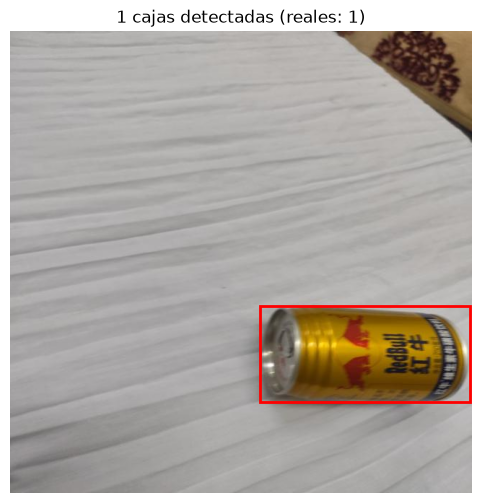

[Caja(x=345.4957275390625, y=380.6053466796875, w=291.124267578125, h=133.454345703125, conf_det=0.28491705656051636, clase='car', conf_cls=None, indice_imagen=0)]


In [13]:
# 12. El detector como lo usa el sistema: src/vision/detector.py -> list[Caja] en píxeles
from src.vision.detector import Detector, PESOS_1CLASE

pesos = PESOS_1CLASE if PESOS_1CLASE.exists() else DIR_MODELOS / 'yolo26n.pt'
print('Pesos:', pesos, '' if PESOS_1CLASE.exists() else '(PENDIENTE el entrenado: se usa COCO solo para mostrar la interfaz)')
det = Detector(pesos, conf=UMBRAL_DET)
if cands:
    cajas = det.detectar(img_ej)
    fig, ax = plt.subplots(figsize=(6, 6)); ax.imshow(Image.open(img_ej)); ax.axis('off')
    for c in cajas:
        ax.add_patch(patches.Rectangle((c.x, c.y), c.w, c.h, fill=False, color='red', lw=2))
    ax.set_title(f'{len(cajas)} cajas detectadas (reales: {len(lineas)})')
    plt.show()
    print(cajas[:3])